# NSF [N II] dispersion near peak ram pressure

This notebook follows up the left panel of cell 33 in `20261021_plot_paper_2.ipynb`. It asks whether the visual resemblance of close-to-peak to post-peak depends on spaxel weighting or on specific close-to-peak galaxies.

## Inputs and selection

The notebook uses the local 7000-run products and copies the Paper II product discovery, stage assignments, combined-cube segmentation, and NSF selection. It requires inclination < 80° and finite `SNR_POSTFIT > 25` in the common usable footprint. NSF is the usable subset remaining after SF and Balmer non-detections. The diagnostic requires finite positive instrumental-resolution-corrected [N II] λ6583 dispersion. The selected NSF spaxels cover all radii and stellar surface densities.

Both estimators use 20 km/s bins across 0–300 km/s. The displayed range extends to 160 km/s to show eight complete bins. Every selected spaxel counts in its denominator, including those above the displayed range and above the histogram grid. The bootstrap resamples whole galaxies. `pooled_weight` below is the fraction of the close-to-peak spaxel sample contributed by each galaxy.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}

RANDOM_SEED = 42
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}
GALAXY_COLORS = {}
for palette_line in (PROJECT_ROOT / 'MAUVE_galaxy_colors.dat').read_text().splitlines():
    if not palette_line.strip() or palette_line.lstrip().startswith('#'):
        continue
    fields = palette_line.split()
    if fields[1] != 'TOTAL_ASSEMBLED':
        GALAXY_COLORS[fields[1]] = fields[3]

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 22, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
N_BOOTSTRAP = 10_000
DISPERSION_BIN_WIDTH = 20  # km/s
DISPERSION_HIST_EDGES = np.arange(0, 300 + DISPERSION_BIN_WIDTH, DISPERSION_BIN_WIDTH)
DISPERSION_HIST_X_LIMITS = (0.0, 160.0)  # display only; tails remain in denominators
DISPERSION_HIST_LOG_LIMITS = (-5.0, 0.0)

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return 0.0
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    for name in ('LOGSFR_SURFACE_DENSITY', 'LOGSFR_SURFACE_DENSITY_HII',
                 'LOGSFR_SURFACE_DENSITY_UPPER'):
        gas_arrays[name] += delta
    return delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths




In [3]:
inventory_rows, histogram_rows = [], []
close_bin_support = {}
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,product_id=product_id,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'NII6583_SIGMA', 'NII6583_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    apply_component_inclination(product_id, component, mass, arrays)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))

    nii_sigma2 = arrays['NII6583_SIGMA']**2 - arrays['NII6583_SIGMA_CORR']**2
    nii_sigma = np.sqrt(np.where(np.isfinite(nii_sigma2) & (nii_sigma2 > 0), nii_sigma2, np.nan))
    selected = nsf & np.isfinite(nii_sigma) & (nii_sigma > 0)
    values = nii_sigma[selected]
    hist, _ = np.histogram(values, bins=DISPERSION_HIST_EDGES)
    above_grid = int((values > DISPERSION_HIST_EDGES[-1]).sum())
    assert hist.sum() + above_grid == len(values)
    if meta['stage'] == 2:
        gas_ids = arrays['BIN_ID'][selected]
        # Match np.histogram: include the right edge only in the final bin.
        velocity_bin = np.searchsorted(DISPERSION_HIST_EDGES, values, side='right') - 1
        velocity_bin[values == DISPERSION_HIST_EDGES[-1]] = len(hist) - 1
        spaxel_counts = np.bincount(velocity_bin, minlength=len(hist) + 1)
        assert np.array_equal(spaxel_counts, np.r_[hist, above_grid])
        gas_bin_counts = np.array([np.unique(gas_ids[velocity_bin == j]).size
                                   for j in range(len(spaxel_counts))])
        assert np.all(gas_bin_counts <= spaxel_counts)
        close_bin_support[gal] = pd.DataFrame({'Spaxels': spaxel_counts, 'Gas bins': gas_bin_counts})
    histogram_rows.append(dict(galaxy=gal, stage=meta['stage'], hist=hist,
                               N_total=len(values), N_above_grid=above_grid,
                               N_above_display=int((values > DISPERSION_HIST_X_LIMITS[1]).sum())))

inventory = pd.DataFrame(inventory_rows)
galaxy_histograms = pd.DataFrame(histogram_rows).set_index('galaxy', verify_integrity=True).sort_index()
stage_ids = {stage: galaxy_histograms.index[galaxy_histograms.stage.eq(stage)].tolist()
             for stage in STAGE_LABELS}
assert all(stage_ids.values()), 'Each infall stage needs at least one included galaxy'
close_ids = galaxy_histograms.index[galaxy_histograms.stage.eq(2) & galaxy_histograms.N_total.gt(0)].tolist()
assert len(close_ids) >= 2, 'Leave-one-out needs two or more contributing close-to-peak galaxies'
display(galaxy_histograms.groupby('stage').agg(
    N_galaxies=('N_total', 'size'), N_contributing=('N_total', lambda totals: totals.gt(0).sum()),
    N_NSF_sigma=('N_total', 'sum')).rename(index=STAGE_LABELS))
display(galaxy_histograms.loc[stage_ids[2], ['N_total', 'N_above_display', 'N_above_grid']]
        .assign(pooled_weight=lambda table: table.N_total / table.N_total.sum()))
display(inventory.loc[inventory.status.ne('included'), ['galaxy', 'stage', 'status']])

,N_galaxies,N_contributing,N_NSF_sigma
stage,,,
Pre-peak,8,8,574080
Close-to-peak,5,5,497018
Post-peak,16,16,1240147


,N_total,N_above_display,N_above_grid,pooled_weight
galaxy,,,,
NGC4298,42065,0,0,0.084635
NGC4424,40964,330,330,0.082420
NGC4501,264733,506,330,0.532643
NGC4654,121453,0,0,0.244363
NGC4694,27803,62,7,0.055940


,galaxy,stage,status
3,NGC4192,1,excluded: inclination >=80 or unavailable
4,NGC4216,3,excluded: inclination >=80 or unavailable
5,NGC4222,1,excluded: inclination >=80 or unavailable
10,NGC4302,2,excluded: inclination >=80 or unavailable
11,NGC4321,1,missing: gas
12,NGC4330,2,excluded: inclination >=80 or unavailable
16,NGC4388,2,excluded: inclination >=80 or unavailable
18,NGC4396,1,excluded: inclination >=80 or unavailable
19,NGC4402,2,excluded: inclination >=80 or unavailable
26,NGC4522,2,excluded: inclination >=80 or unavailable


## 1. Equal-galaxy left panel with wider bins

Each bin shows the mean of the per-galaxy fractions among galaxies with at least one selected spaxel. Error bars show the 16th–84th percentiles from 10,000 whole-galaxy bootstrap draws where at least two galaxies support the bin. Downward markers indicate a lower bound of zero.

In [4]:
def normalized_histogram_bootstrap(histograms, totals, multiplicities, branch='pooled_spaxel'):
    """Bin fractions with pooled-spaxel or equal-galaxy central and bootstrap weights."""
    histograms = np.asarray(histograms, dtype=float)
    totals = np.asarray(totals, dtype=float)
    assert histograms.ndim == 2 and histograms.shape[0] == len(totals)
    assert np.all(histograms >= 0) and np.all(totals >= 0)
    assert np.all(histograms.sum(axis=1) <= totals)
    if branch == 'equal_galaxy':
        eligible = totals > 0
        values = np.divide(histograms, totals[:, None], out=np.zeros_like(histograms),
                           where=totals[:, None] > 0)
        weights = eligible.astype(float)
    elif branch == 'pooled_spaxel':
        values, weights = histograms, totals
    else:
        raise ValueError(f'Unknown distribution estimator: {branch}')
    central = values.sum(axis=0) / weights.sum() if weights.sum() else np.full(histograms.shape[1], np.nan)
    # Direct sums avoid spurious floating-point warnings from the local matmul backend.
    boot_denominator = np.einsum('bg,g->b', multiplicities, weights, optimize=False)
    boot_numerator = np.einsum('bg,gj->bj', multiplicities, values, optimize=False)
    boot = np.divide(boot_numerator, boot_denominator[:, None],
        out=np.full((len(multiplicities), histograms.shape[1]), np.nan), where=boot_denominator[:, None] > 0)
    finite_draws = boot_denominator > 0
    assert np.isfinite(boot[finite_draws]).all()
    assert np.all((boot[finite_draws] >= 0) & (boot[finite_draws] <= 1 + 1e-12))
    return central, boot, finite_draws

from matplotlib.lines import Line2D

def draw_dispersion_distribution(ax, panel, color, filled, linestyle, label=None):
    positive = panel.loc[panel.probability.gt(0)].sort_values('center')
    if positive.empty:
        return
    x = positive.center.to_numpy(float)
    y = np.log10(positive.probability.to_numpy(float))
    ax.plot(x, y, color=color, marker='o', ms=3.2, lw=0.9, ls=linestyle,
            markerfacecolor=color if filled else 'white', markeredgewidth=0.8, label=label)
    band = positive.loc[positive.N_products_in_bin.ge(2) & positive.lo.notna() & positive.hi.gt(0)]
    if len(band):
        floor = 10.0 ** DISPERSION_HIST_LOG_LIMITS[0]
        lower = np.log10(np.maximum(band.lo.to_numpy(float), floor))
        upper = np.log10(np.maximum(band.hi.to_numpy(float), floor))
        ax.vlines(band.center, lower, upper, color=color, lw=0.7, alpha=0.65)
        zero_bound = band.lo.le(0)
        ax.plot(band.loc[zero_bound, 'center'], np.full(int(zero_bound.sum()), DISPERSION_HIST_LOG_LIMITS[0]),
                marker='v', ms=3, linestyle='none', color=color, clip_on=False)

In [5]:
def make_profile(ids, stage, branch='equal_galaxy'):
    sample = galaxy_histograms.loc[ids]
    hist = np.stack(sample['hist'])
    totals = sample.N_total.to_numpy()
    n = len(ids)
    rng = np.random.default_rng(RANDOM_SEED + 23_000_000 + stage)
    draws = rng.multinomial(n, np.full(n, 1 / n), size=N_BOOTSTRAP)
    central, boot, finite = normalized_histogram_bootstrap(hist, totals, draws, branch)
    support = (hist > 0).sum(axis=0)
    bounds = np.percentile(boot[finite], [16, 84], axis=0) if finite.any() else np.full((2, len(central)), np.nan)
    bounds[:, support < 2] = np.nan
    centers = (DISPERSION_HIST_EDGES[:-1] + DISPERSION_HIST_EDGES[1:]) / 2
    return pd.DataFrame(dict(center=centers, probability=central, lo=bounds[0], hi=bounds[1],
                             N_products_in_bin=support))


DISPERSION_LABEL = r'$\sigma_{\mathrm{[N\,II]}6583,\mathrm{int}}$ [km s$^{-1}$]'
EQUAL_LABEL = r'$\log_{10}\langle N_{g,\rm bin}/N_{g,\rm tot}\rangle_g$'
POOLED_LABEL = r'$\log_{10}(N_{\rm bin}/N_{\rm tot})$'


def format_axis(ax):
    ax.set(xlim=DISPERSION_HIST_X_LIMITS, ylim=DISPERSION_HIST_LOG_LIMITS)
    ax.tick_params(top=True, right=True)
    ax.minorticks_on()
    ax.grid(alpha=0.15)


def plot_stages(profiles, ylabel):
    fig, ax = plt.subplots(figsize=(7.4, 5.4), layout='constrained')
    for stage, panel in profiles.items():
        draw_dispersion_distribution(ax, panel, STAGE_COLORS[stage], filled=True,
                                     linestyle='-', label=STAGE_LABELS[stage])
    format_axis(ax)
    ax.set(title='[N II] intrinsic dispersion', xlabel=DISPERSION_LABEL, ylabel=ylabel)
    ax.legend(frameon=False, loc='upper center', ncol=3, fontsize=12)
    plt.show()
    plt.close(fig)


def plot_close_peak_cases(cases, case_label, use_galaxy_colors=False):
    ncols = min(3, len(cases))
    nrows = (len(cases) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.25 * nrows + 0.6),
                             sharex=True, sharey=True, squeeze=False)
    fig.subplots_adjust(left=0.085, right=0.98, bottom=0.30 / nrows,
                        top=1 - 0.26 / nrows, wspace=0.16, hspace=0.48)
    for ax, (galaxy, panel) in zip(axes.flat, cases.items()):
        for stage in (1, 3):
            draw_dispersion_distribution(ax, equal_profiles[stage], STAGE_COLORS[stage],
                                         filled=True, linestyle='-')
        draw_dispersion_distribution(ax, equal_profiles[2].assign(lo=np.nan, hi=np.nan),
                                     STAGE_COLORS[2], filled=False, linestyle='--')
        color = GALAXY_COLORS[galaxy] if use_galaxy_colors else STAGE_COLORS[2]
        draw_dispersion_distribution(ax, panel, color, filled=True, linestyle='-')
        format_axis(ax)
        ax.set_title(f'{case_label} {galaxy}')
    for ax in list(axes.flat)[len(cases):]:
        ax.set_visible(False)
    for ax in list(axes.flat)[:len(cases)]:
        ax.tick_params(labelbottom=True)
    handles = [
        Line2D([], [], color=STAGE_COLORS[1], label=STAGE_LABELS[1]),
        Line2D([], [], color=STAGE_COLORS[2], linestyle='--', label='Full close-to-peak'),
        Line2D([], [], color=STAGE_COLORS[3], label=STAGE_LABELS[3]),
        Line2D([], [], color='0.35' if use_galaxy_colors else STAGE_COLORS[2],
               marker='o', label='Close-to-peak subset'),
    ]
    fig.legend(handles=handles, loc='upper center', frameon=False, ncol=4, fontsize=11)
    fig.supxlabel(DISPERSION_LABEL)
    fig.supylabel(EQUAL_LABEL)
    plt.show()
    plt.close(fig)

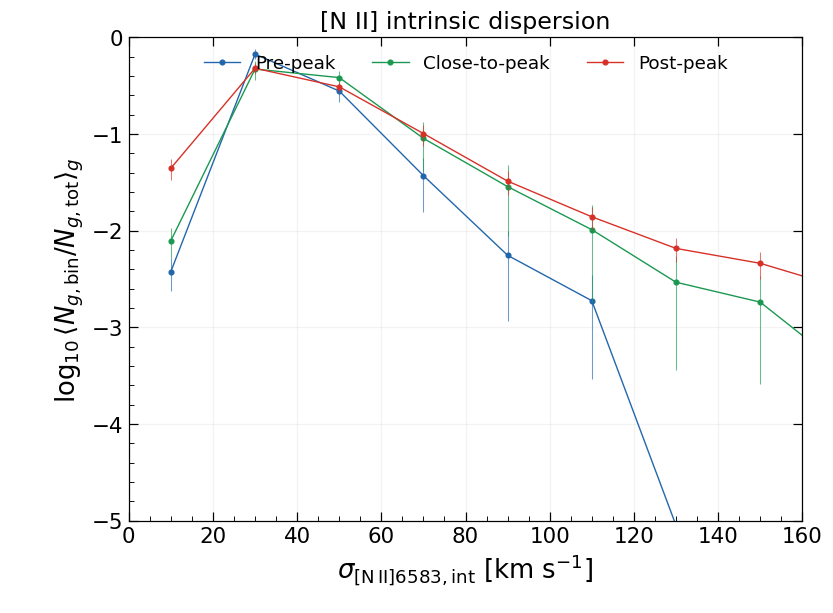

In [6]:
equal_profiles = {stage: make_profile(ids, stage) for stage, ids in stage_ids.items()}
plot_stages(equal_profiles, EQUAL_LABEL)

## 2. Pool spaxels within each stage

Each curve divides the stage's summed bin counts by its summed sample size. Galaxies with more selected NSF spaxels contribute more weight. The bars still resample whole galaxies.

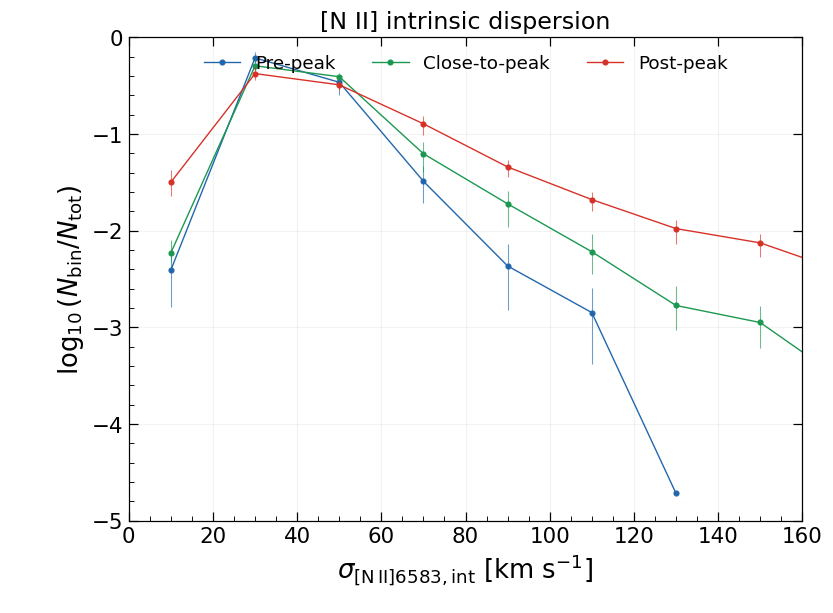

In [7]:
pooled_profiles = {stage: make_profile(ids, stage, 'pooled_spaxel')
                   for stage, ids in stage_ids.items()}
plot_stages(pooled_profiles, POOLED_LABEL)

## 3. Leave out one close-to-peak galaxy at a time

Each panel begins with the full stage sample, omits the named galaxy, and recomputes the close-to-peak curve and bootstrap. The equal-galaxy pre-peak and post-peak curves and the dashed full close-to-peak curve are fixed across panels.

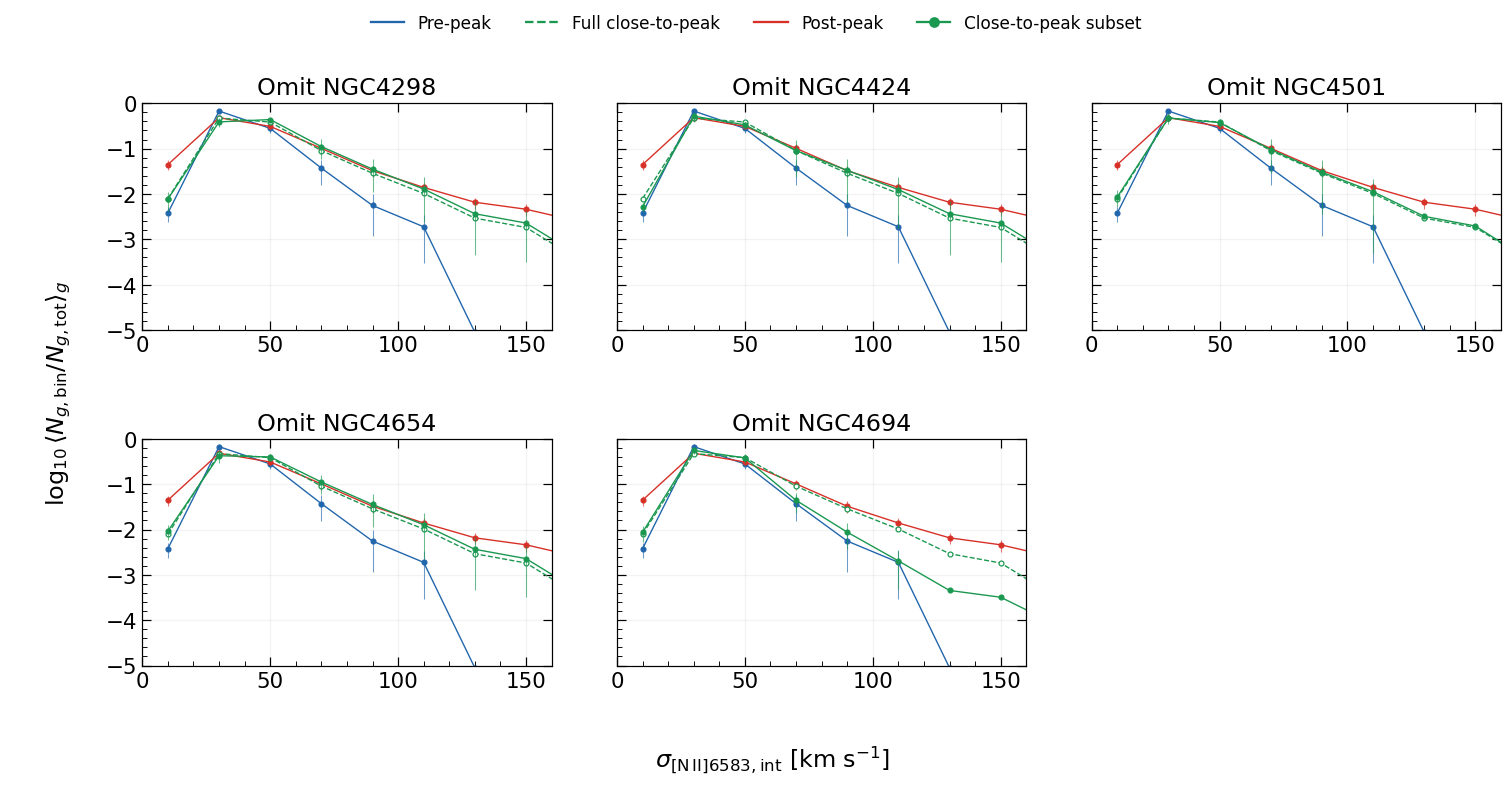

In [8]:
omission_order = sorted(close_ids, key=lambda galaxy: (galaxy != 'NGC4298', galaxy))
leave_one_out_ids = {galaxy: [other for other in stage_ids[2] if other != galaxy]
                     for galaxy in omission_order}
leave_one_out = {galaxy: make_profile(ids, 2) for galaxy, ids in leave_one_out_ids.items()}
plot_close_peak_cases(leave_one_out, 'Omit')

## 4. Use one close-to-peak galaxy at a time

Each panel shows the named galaxy's own spaxel distribution in its MAUVE colour with the same stage reference curves. The single-galaxy curve has no between-galaxy bootstrap interval.

The table counts the selected NSF spaxels and the distinct gas `BIN_ID` values they occupy in each dispersion interval. Counts of gas bins are unique within each galaxy and interval. A gas bin can appear in multiple rows if its selected spaxels span multiple intervals. The overflow row accounts for spaxels above the histogram grid.

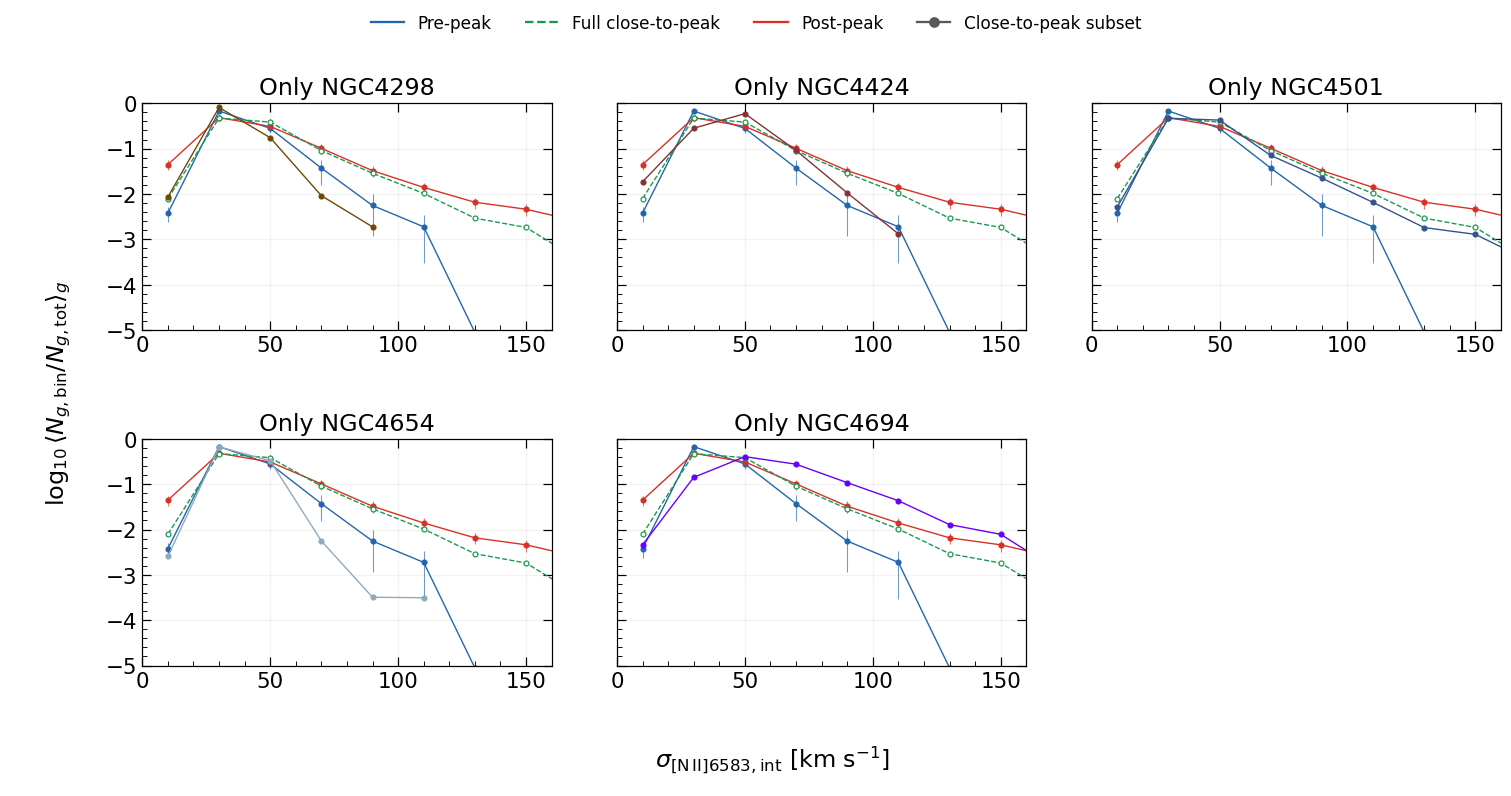

NGC4298          NGC4424  ...  NGC4654 NGC4694         
                         Spaxels Gas bins Spaxels  ... Gas bins Spaxels Gas bins
[N II] dispersion (km/s)                           ...                          
0–20                         360       21     759  ...        6     128       17
20–40                      33925     1911   11519  ...     2553    3938      696
40–60                       7316      764   24143  ...     2864   11236     2628
60–80                        385       24    3727  ...      120    7664     1118
80–100                        79        7     432  ...        1    3001      368
100–120                        0        0      54  ...        1    1199      112
120–140                        0        0       0  ...        0     357       35
140–160                        0        0       0  ...        0     218       22
160–180                        0        0       0  ...        0      42        6
180–200                        0        0       0  ...        0       0        0
200–220                        0        0       0  ...        0      10        2
220–240                        0        0       0  ...        0       0        0
240–260                        0        0       0  ...        0       0        0
260–280                        0        0       0  ...        0       0        0
280–300                        0        0       0  ...        0       3        1
>300                           0        0     330  ...        0       7        2

[16 rows x 10 columns]

In [9]:
single_galaxy = {galaxy: make_profile([galaxy], 2) for galaxy in close_ids}
plot_close_peak_cases(single_galaxy, 'Only', use_galaxy_colors=True)

interval_labels = [f'{lo:g}–{hi:g}' for lo, hi in zip(DISPERSION_HIST_EDGES[:-1], DISPERSION_HIST_EDGES[1:])]
interval_labels.append(f'>{DISPERSION_HIST_EDGES[-1]:g}')
close_to_peak_bin_counts = pd.concat(close_bin_support, axis=1).sort_index(axis=1, level=0, sort_remaining=False)
close_to_peak_bin_counts.index = pd.Index(interval_labels, name='[N II] dispersion (km/s)')
display(close_to_peak_bin_counts)

## 5. Compare the shapes numerically

Total variation (TV) is half the sum of absolute differences in linear bin probability. It uses all histogram bins and a single overflow bin above 300 km/s. A negative `post_minus_pre` means closer to post-peak. The pooled case compares with pooled references. All other cases use the fixed equal-galaxy references. These distances describe sensitivity to the sample and estimator.

In [10]:
def probability_vector(ids, branch):
    sample = galaxy_histograms.loc[ids]
    sample = sample[sample.N_total.gt(0)]
    counts_with_tail = np.column_stack((np.stack(sample['hist']), sample.N_above_grid))
    totals = sample.N_total.to_numpy()
    if branch == 'equal_galaxy':
        return (counts_with_tail / totals[:, None]).mean(axis=0)
    return counts_with_tail.sum(axis=0) / totals.sum()


def compare(label, ids, branch):
    close = probability_vector(ids, branch)
    pre = probability_vector(stage_ids[1], branch)
    post = probability_vector(stage_ids[3], branch)
    for probabilities in (close, pre, post):
        assert np.isclose(probabilities.sum(), 1)
    d_pre = 0.5 * np.abs(close - pre).sum()
    d_post = 0.5 * np.abs(close - post).sum()
    return dict(case=label, N_contributing=int(galaxy_histograms.loc[ids, 'N_total'].gt(0).sum()),
                TV_pre=d_pre, TV_post=d_post, post_minus_pre=d_post - d_pre,
                nearer='Tie' if np.isclose(d_pre, d_post) else 'Post-peak' if d_post < d_pre else 'Pre-peak')


distance_summary = pd.DataFrame([
    compare('Full equal-galaxy', stage_ids[2], 'equal_galaxy'),
    compare('Full pooled spaxels', stage_ids[2], 'pooled_spaxel'),
    *(compare(f'Omit {galaxy}', leave_one_out_ids[galaxy], 'equal_galaxy') for galaxy in close_ids),
    *(compare(f'Only {galaxy}', [galaxy], 'equal_galaxy') for galaxy in close_ids),
]).set_index('case')
display(distance_summary.round(4))

,N_contributing,TV_pre,TV_post,post_minus_pre,nearer
case,,,,,
Full equal-galaxy,5,0.2012,0.0758,-0.1254,Post-peak
Full pooled spaxels,5,0.1049,0.1562,0.0513,Pre-peak
Omit NGC4298,4,0.2850,0.1407,-0.1443,Post-peak
Omit NGC4424,4,0.1537,0.0640,-0.0897,Post-peak
Omit NGC4501,4,0.1998,0.0656,-0.1341,Post-peak
Omit NGC4654,4,0.2489,0.1032,-0.1457,Post-peak
Omit NGC4694,4,0.1188,0.1449,0.0261,Pre-peak
Only NGC4298,1,0.1386,0.3264,0.1879,Pre-peak
Only NGC4424,1,0.3921,0.2869,-0.1052,Post-peak


## Results with 20 km/s bins, 20 November 2026

- Across the same 0–160 km/s display range, the median close-to-peak count per bin rises from about 1,596 spaxels at 5 km/s to 6,225 at 20 km/s. All eight wide bins contain spaxels from at least two galaxies. The close-to-peak sample still contains five galaxies.
- The full equal-galaxy close-to-peak distribution is nearer post-peak by total variation (0.076 to post-peak, 0.201 to pre-peak). The pooled comparison is nearer pre-peak (0.105 to pre-peak, 0.156 to post-peak). NGC4501 and NGC4654 together supply 77.7% of the close-to-peak spaxels.
- Omitting NGC4298 still leaves the distribution closer to post-peak. NGC4694 is still the only omission that switches the nearer reference to pre-peak.
- The single-galaxy distributions for NGC4424, NGC4501, and NGC4694 are closer to post-peak at this resolution. NGC4298 and NGC4654 are closer to pre-peak. NGC4501 was nearly tied at 5 km/s, showing that its comparison depends on bin width.

The local run includes 29 galaxies (8 pre-peak, 5 close-to-peak, 16 post-peak). The NGC4321 7000-run gas map was unavailable, so this run has one fewer pre-peak galaxy than the saved Paper II outputs.